# AlexNet Fine-Tuning on MNIST


## 1. Kaggle environment and reproducibility


In [1]:
from pathlib import Path
import gzip
import hashlib
import importlib.metadata
import json
import platform
import random
import struct
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), 'Enable a GPU in Kaggle before continuing.'
device = torch.device('cuda:0')
RESULTS_DIR = Path('/kaggle/working/results')
PLOTS_DIR = Path('/kaggle/working/plots')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

environment = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(device),
    'cuda_runtime': torch.version.cuda,
    'seed': SEED,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']},
}
print(json.dumps(environment, indent=2))
(RESULTS_DIR / 'mnist_environment.json').write_text(json.dumps(environment, indent=2))


{
  "python": "3.13.15",
  "gpu": "Tesla T4",
  "cuda_runtime": "12.8",
  "seed": 42,
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0"
  }
}


272

### GPU smoke check


In [2]:
smoke_model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10)).to(device)
smoke_x = torch.rand(8, 1, 28, 28, device=device)
smoke_y = torch.arange(8, device=device)
smoke_loss = nn.CrossEntropyLoss()(smoke_model(smoke_x), smoke_y)
smoke_loss.backward()
assert torch.isfinite(smoke_loss)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in smoke_model.parameters())
print('PASS: GPU forward pass, cross-entropy, and finite gradients.')
del smoke_model, smoke_x, smoke_y, smoke_loss
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


PASS: GPU forward pass, cross-entropy, and finite gradients.


## 2. Locate and validate MNIST


In [3]:
INPUT_DIR = Path('/kaggle/input')
file_names = {
    'train_images': 'train-images-idx3-ubyte',
    'train_labels': 'train-labels-idx1-ubyte',
    'test_images': 't10k-images-idx3-ubyte',
    'test_labels': 't10k-labels-idx1-ubyte',
}

def read_bytes(path):
    return gzip.decompress(path.read_bytes()) if path.suffix == '.gz' else path.read_bytes()

source_paths = {}
source_hashes = {}
for key, name in file_names.items():
    alternatives = {name, name.replace('-idx', '.idx')}
    accepted_names = alternatives | {n + '.gz' for n in alternatives}
    matches = sorted(p for p in INPUT_DIR.rglob('*') if p.is_file() and p.name in accepted_names)
    assert matches, f'Missing {name}. Attach the MNIST dataset specified in the lab.'
    hashes = {hashlib.sha256(read_bytes(p)).hexdigest() for p in matches}
    assert len(hashes) == 1, f'Conflicting copies of {name}: {matches}'
    source_paths[key] = matches[0]
    source_hashes[key] = hashes.pop()
    print(f'{key}: {matches[0]} ({len(matches)} matching copies)')

def read_idx(path):
    raw = read_bytes(path)
    assert len(raw) >= 8, f'Incomplete IDX header: {path}'
    magic, count = struct.unpack('>II', raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack('>II', raw[8:16])
        assert (rows, cols) == (28, 28)
        assert len(raw) == 16 + count * rows * cols
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols).copy()
    assert magic == 2049, f'Unexpected IDX magic number: {magic}'
    assert len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

official_train_images = read_idx(source_paths['train_images'])
official_train_labels = read_idx(source_paths['train_labels'])
official_test_images = read_idx(source_paths['test_images'])
official_test_labels = read_idx(source_paths['test_labels'])
assert official_train_images.shape == (60000, 28, 28)
assert official_test_images.shape == (10000, 28, 28)
assert official_train_labels.shape == (60000,)
assert official_test_labels.shape == (10000,)
for labels in (official_train_labels, official_test_labels):
    assert np.array_equal(np.unique(labels), np.arange(10))
print('Official training images:', official_train_images.shape)
print('Official test images:', official_test_images.shape)
print('Pixel dtype:', official_train_images.dtype)
print('Training pixel range:', official_train_images.min(), official_train_images.max())
print('PASS: IDX sizes, image dimensions, and label ranges.')


train_images: /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte (2 matching copies)
train_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte (2 matching copies)
test_images: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte (2 matching copies)
test_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte (2 matching copies)
Official training images: (60000, 28, 28)
Official test images: (10000, 28, 28)
Pixel dtype: uint8
Training pixel range: 0 255
PASS: IDX sizes, image dimensions, and label ranges.


## 3. Shared train, validation, and test partitions


In [4]:
train_indices, validation_indices = train_test_split(
    np.arange(len(official_train_labels)),
    test_size=6000,
    random_state=SEED,
    stratify=official_train_labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
test_indices = np.arange(len(official_test_labels))
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(60000))

split_manifest = pd.concat([
    pd.DataFrame({'split': 'train', 'source': 'official_train', 'source_index': train_indices}),
    pd.DataFrame({'split': 'validation', 'source': 'official_train', 'source_index': validation_indices}),
    pd.DataFrame({'split': 'test', 'source': 'official_test', 'source_index': test_indices}),
], ignore_index=True)
assert not split_manifest.duplicated(['source', 'source_index']).any()
manifest_text = split_manifest.to_csv(index=False, lineterminator='\n')
split_hash = hashlib.sha256(manifest_text.encode()).hexdigest()
(RESULTS_DIR / 'mnist_split_manifest.csv').write_text(manifest_text)

split_labels = {
    'train': official_train_labels[train_indices],
    'validation': official_train_labels[validation_indices],
    'test': official_test_labels,
}
class_counts = pd.DataFrame({name: np.bincount(labels, minlength=10) for name, labels in split_labels.items()})
class_counts.index.name = 'digit'
assert (class_counts > 0).all().all()
display(class_counts)
class_counts.to_csv(RESULTS_DIR / 'mnist_split_class_counts.csv')
print('Partition sizes:', {name: len(labels) for name, labels in split_labels.items()})
print('Split SHA256:', split_hash)
print('PASS: disjoint source indices, full coverage, and all ten classes in each partition.')


,train,validation,test
digit,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


Partition sizes: {'train': 54000, 'validation': 6000, 'test': 10000}
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: disjoint source indices, full coverage, and all ten classes in each partition.


### Training examples and class distribution


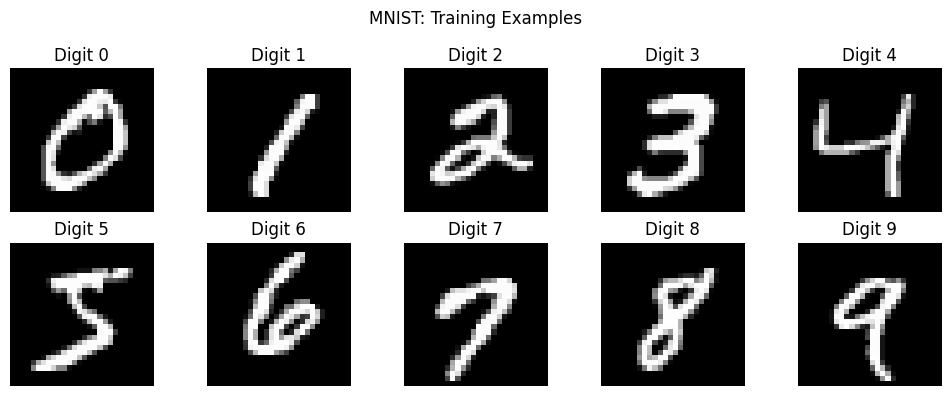

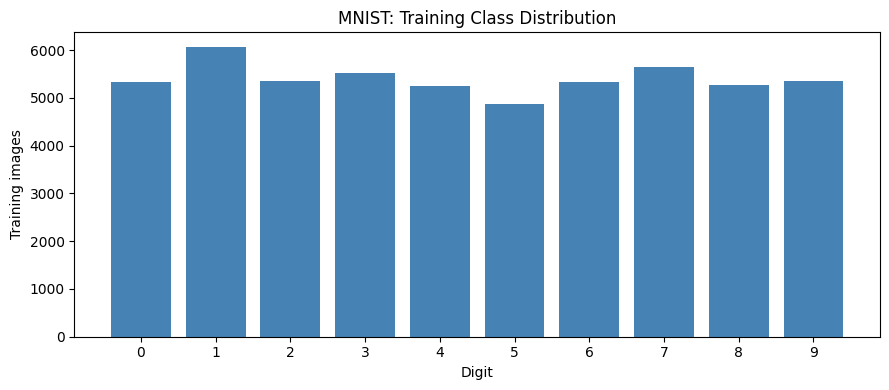

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    index = train_indices[np.flatnonzero(official_train_labels[train_indices] == digit)[0]]
    ax.imshow(official_train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
fig.suptitle('MNIST: Training Examples')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_examples.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_counts.index, class_counts['train'], color='steelblue')
ax.set(xticks=range(10), xlabel='Digit', ylabel='Training images', title='MNIST: Training Class Distribution')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()


## 4. Shared input and evaluation conventions


In [6]:
X_train = torch.from_numpy(official_train_images[train_indices]).unsqueeze(1).float().div(255)
y_train = torch.from_numpy(official_train_labels[train_indices].astype(np.int64))
X_validation = torch.from_numpy(official_train_images[validation_indices]).unsqueeze(1).float().div(255)
y_validation = torch.from_numpy(official_train_labels[validation_indices].astype(np.int64))
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)
assert y_train.dtype == torch.int64
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64,
                          shuffle=True, generator=loader_generator, num_workers=0,
                          worker_init_fn=seed_worker, pin_memory=True)
validation_loader = DataLoader(TensorDataset(X_validation, y_validation), batch_size=64,
                               shuffle=False, num_workers=0, pin_memory=True)

def classification_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=np.arange(10), average='macro', zero_division=0)),
    }

def gpu_time():
    torch.cuda.synchronize(device)
    return time.perf_counter()

print('Training tensors:', X_train.shape, y_train.shape)
print('Validation tensors:', X_validation.shape, y_validation.shape)
print('Input dtype:', X_train.dtype, '| Target dtype:', y_train.dtype)
print('Batches per training epoch:', len(train_loader))
print('PASS: tensors and data loaders ready. No test predictions computed.')


Training tensors: torch.Size([54000, 1, 28, 28]) torch.Size([54000])
Validation tensors: torch.Size([6000, 1, 28, 28]) torch.Size([6000])
Input dtype: torch.float32 | Target dtype: torch.int64
Batches per training epoch: 844
PASS: tensors and data loaders ready. No test predictions computed.


### Faster R-CNN adaptation and setup export


In [7]:
setup_config = {
    'dataset': 'hojjatk/mnist-dataset',
    'seed': SEED,
    'source_sha256': source_hashes,
    'split_sha256': split_hash,
    'partition_sizes': {name: len(labels) for name, labels in split_labels.items()},
    'split_policy': 'Stratified holdout from official train; official test kept separate',
    'cnn_vit_input': 'float32 grayscale pixels / 255; NCHW',
    'class_labels': list(range(10)),
    'metrics': ['accuracy', 'macro_f1', 'loss', 'training_seconds'],
    'selection_data': 'validation only',
    'timing': 'CUDA synchronized; includes per-epoch validation; excludes downloads',
    'faster_rcnn': {
        'box_policy': 'one derived full-image box per image',
        'background_label': 0,
        'digit_to_detector_label': 'digit + 1',
        'image_prediction': 'highest-scoring detection; no detection counts as incorrect',
        'score_threshold': 'to be fixed using validation in Issue 3',
        'loss_note': 'detection loss is not directly comparable to classifier cross-entropy',
    },
    'test_predictions_computed': False,
}
(RESULTS_DIR / 'mnist_setup_config.json').write_text(json.dumps(setup_config, indent=2))
print('Saved setup configuration:', RESULTS_DIR / 'mnist_setup_config.json')
print('PASS: Issue 1 setup cells completed. Review outputs before closing the issue.')


Saved setup configuration: /kaggle/working/results/mnist_setup_config.json
PASS: Issue 1 setup cells completed. Review outputs before closing the issue.


## 5. Model experiment


In [8]:
from torchvision.models import AlexNet_Weights

expected_split_hash = (
    "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
)
assert split_hash == expected_split_hash
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)

alex_weights = AlexNet_Weights.IMAGENET1K_V1
alex_transform = alex_weights.transforms()

alex_sample_grayscale = X_train[:8]
alex_sample_rgb = alex_sample_grayscale.repeat(1, 3, 1, 1)
alex_sample_inputs = alex_transform(alex_sample_rgb)

assert alex_sample_inputs.shape == (8, 3, 224, 224)
assert alex_sample_inputs.dtype == torch.float32
assert torch.isfinite(alex_sample_inputs).all()
assert torch.equal(alex_sample_rgb[:, 0], alex_sample_rgb[:, 1])
assert torch.equal(alex_sample_rgb[:, 1], alex_sample_rgb[:, 2])

print("Pretrained weights:", alex_weights.name)
print("Transforms:", alex_transform)
print("Original sample shape:", tuple(alex_sample_grayscale.shape))
print("AlexNet input shape:", tuple(alex_sample_inputs.shape))
print(
    "Normalized pixel range:",
    round(alex_sample_inputs.min().item(), 4),
    round(alex_sample_inputs.max().item(), 4),
)
print("Visible GPUs:", torch.cuda.device_count())
print("PASS: shared split matches; AlexNet input transforms are valid.")
print("No model training or test evaluation performed.")

Pretrained weights: IMAGENET1K_V1
Transforms: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Original sample shape: (8, 1, 28, 28)
AlexNet input shape: (8, 3, 224, 224)
Normalized pixel range: -2.1179 2.6395
Visible GPUs: 2
PASS: shared split matches; AlexNet input transforms are valid.
No model training or test evaluation performed.


In [9]:
from torchvision.models import alexnet

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

alex_model = alexnet(weights=alex_weights)

for parameter in alex_model.parameters():
    parameter.requires_grad = False

alex_model.classifier[6] = nn.Linear(
    alex_model.classifier[6].in_features,
    10,
)

alex_model = alex_model.to(device)
alex_criterion = nn.CrossEntropyLoss()

alex_model.eval()
with torch.no_grad():
    alex_sample_logits = alex_model(alex_sample_inputs.to(device))
    alex_sample_loss = alex_criterion(
        alex_sample_logits,
        y_train[:8].to(device),
    )

assert alex_sample_logits.shape == (8, 10)
assert torch.isfinite(alex_sample_logits).all()
assert torch.isfinite(alex_sample_loss)

alex_total_parameters = sum(p.numel() for p in alex_model.parameters())
alex_trainable_parameters = sum(
    p.numel() for p in alex_model.parameters() if p.requires_grad
)

print("Feature extractor:", alex_model.features)
print("Classifier:", alex_model.classifier)
print(f"Total parameters: {alex_total_parameters:,}")
print(f"Warm-up trainable parameters: {alex_trainable_parameters:,}")
print("Trainable tensors:")
for name, parameter in alex_model.named_parameters():
    if parameter.requires_grad:
        print(f"  {name}: {tuple(parameter.shape)}")

print("Output shape:", tuple(alex_sample_logits.shape))
print("Device:", next(alex_model.parameters()).device)
print("PASS: pretrained AlexNet loaded; ten-class forward pass is finite.")
print("No optimizer updates or test evaluation performed.")

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 234MB/s]  


Feature extractor: Sequential(
  (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU(inplace=True)
  (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU(inplace=True)
  (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Classifier: Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=409

In [10]:
alex_config = {
    "seed": SEED,
    "architecture": "AlexNet",
    "pretrained_weights": alex_weights.name,
    "num_classes": 10,
    "resize_size": 256,
    "crop_size": 224,
    "normalization_mean": list(alex_transform.mean),
    "normalization_std": list(alex_transform.std),
    "optimizer": "Adam",
    "global_batch_size": 32,
    "warmup_epochs": 2,
    "warmup_learning_rate": 0.001,
    "warmup_trainable_layers": ["classifier.6"],
    "finetune_epochs": 3,
    "finetune_backbone_learning_rate": 0.00001,
    "finetune_classifier_learning_rate": 0.0001,
    "finetune_trainable_layers": ["features.10 onwards", "classifier"],
    "loss": "CrossEntropyLoss",
    "checkpoint_selection": "lowest validation cross-entropy across both phases",
    "checkpoint_tie_break": "earliest epoch",
    "split_sha256": split_hash,
}

assert isinstance(alex_model.features[10], nn.Conv2d)
assert alex_model.features[10].in_channels == 256
assert alex_model.features[10].out_channels == 256

alex_finetune_parameters = sum(
    p.numel() for p in alex_model.features[10:].parameters()
) + sum(
    p.numel() for p in alex_model.classifier.parameters()
)

print(json.dumps(alex_config, indent=2))
print(f"\nFine-tuning parameters: {alex_finetune_parameters:,}")
print("GPU strategy will be selected after benchmarking.")
print("PASS: training schedule defined; model remains in warm-up configuration.")
print("No optimizer updates or test evaluation performed.")

{
  "seed": 42,
  "architecture": "AlexNet",
  "pretrained_weights": "IMAGENET1K_V1",
  "num_classes": 10,
  "resize_size": 256,
  "crop_size": 224,
  "normalization_mean": [
    0.485,
    0.456,
    0.406
  ],
  "normalization_std": [
    0.229,
    0.224,
    0.225
  ],
  "optimizer": "Adam",
  "global_batch_size": 32,
  "warmup_epochs": 2,
  "warmup_learning_rate": 0.001,
  "warmup_trainable_layers": [
    "classifier.6"
  ],
  "finetune_epochs": 3,
  "finetune_backbone_learning_rate": 1e-05,
  "finetune_classifier_learning_rate": 0.0001,
  "finetune_trainable_layers": [
    "features.10 onwards",
    "classifier"
  ],
  "loss": "CrossEntropyLoss",
  "checkpoint_selection": "lowest validation cross-entropy across both phases",
  "checkpoint_tie_break": "earliest epoch",
  "split_sha256": "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
}

Fine-tuning parameters: 55,165,194
GPU strategy will be selected after benchmarking.
PASS: training schedule defined; model rem

In [11]:
alex_train_dataset = TensorDataset(X_train, y_train)
alex_validation_dataset = TensorDataset(X_validation, y_validation)

alex_loader_generator = torch.Generator().manual_seed(SEED)

alex_train_loader = DataLoader(
    alex_train_dataset,
    batch_size=alex_config["global_batch_size"],
    shuffle=True,
    generator=alex_loader_generator,
    num_workers=0,
    pin_memory=True,
)

alex_train_eval_loader = DataLoader(
    alex_train_dataset,
    batch_size=alex_config["global_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

alex_validation_loader = DataLoader(
    alex_validation_dataset,
    batch_size=alex_config["global_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

def prepare_alex_inputs(images, target_device):
    images = images.to(target_device, non_blocking=True)
    return alex_transform(images.repeat(1, 3, 1, 1))

with torch.no_grad():
    alex_prepared_sample = prepare_alex_inputs(X_train[:8], device)

assert alex_prepared_sample.shape == (8, 3, 224, 224)
assert alex_prepared_sample.device == next(alex_model.parameters()).device
assert torch.isfinite(alex_prepared_sample).all()
assert torch.allclose(
    alex_prepared_sample.cpu(),
    alex_sample_inputs.cpu(),
    atol=1e-5,
    rtol=1e-5,
)

print("Training images:", len(alex_train_dataset))
print("Validation images:", len(alex_validation_dataset))
print("Global batch size:", alex_config["global_batch_size"])
print("Training batches per epoch:", len(alex_train_loader))
print("Validation batches:", len(alex_validation_loader))
print("Prepared sample shape:", tuple(alex_prepared_sample.shape))
print("Preprocessing device:", alex_prepared_sample.device)
print("PASS: batch preprocessing agrees with the checked sample transforms.")
print("No optimizer updates or test evaluation performed.")

del alex_prepared_sample

Training images: 54000
Validation images: 6000
Global batch size: 32
Training batches per epoch: 1688
Validation batches: 188
Prepared sample shape: (8, 3, 224, 224)
Preprocessing device: cuda:0
PASS: batch preprocessing agrees with the checked sample transforms.
No optimizer updates or test evaluation performed.


In [12]:
def evaluate_alex(model, loader):
    previous_training_mode = model.training
    model.eval()
    model_device = next(model.parameters()).device

    loss_sum = torch.zeros((), device=model_device, dtype=torch.float64)
    sample_count = 0
    collected_labels = []
    collected_predictions = []

    try:
        with torch.inference_mode():
            for images, labels in loader:
                inputs = prepare_alex_inputs(images, model_device)
                labels = labels.to(model_device, non_blocking=True)

                logits = model(inputs)
                batch_loss = nn.functional.cross_entropy(
                    logits, labels, reduction="sum"
                )

                if not torch.isfinite(batch_loss):
                    raise RuntimeError("Non-finite AlexNet evaluation loss.")

                loss_sum += batch_loss.double()
                sample_count += labels.size(0)
                collected_labels.append(labels.cpu())
                collected_predictions.append(logits.argmax(dim=1).cpu())
    finally:
        model.train(previous_training_mode)

    if sample_count == 0:
        raise ValueError("The evaluation loader contains no samples.")

    true_labels = torch.cat(collected_labels).numpy()
    predictions = torch.cat(collected_predictions).numpy()

    metrics = {
        "loss": loss_sum.item() / sample_count,
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            labels=np.arange(10),
            average="macro",
            zero_division=0,
        ),
    }

    return metrics, true_labels, predictions


print("Evaluation function ready.")
print("Loss: sample-weighted mean cross-entropy.")
print("Metrics: accuracy and macro-F1 across all ten digits.")
print("Evaluation disables dropout and restores the previous model mode.")
print("No training or test evaluation performed.")

Evaluation function ready.
Loss: sample-weighted mean cross-entropy.
Metrics: accuracy and macro-F1 across all ten digits.
Evaluation disables dropout and restores the previous model mode.
No training or test evaluation performed.


In [13]:
def benchmark_alex_phase(name, fine_tuning, warmup_steps=1, timed_steps=5):
    for parameter in alex_model.parameters():
        parameter.requires_grad = False

    trainable_modules = (
        [alex_model.features[10:], alex_model.classifier]
        if fine_tuning
        else [alex_model.classifier[6]]
    )
    for module in trainable_modules:
        for parameter in module.parameters():
            parameter.requires_grad = True

    alex_model.train()
    torch.cuda.reset_peak_memory_stats(device)

    def backward_pass():
        alex_model.zero_grad(set_to_none=True)
        inputs = prepare_alex_inputs(alex_benchmark_images, device)
        logits = alex_model(inputs)
        loss = alex_criterion(logits, alex_benchmark_labels)
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss during {name} benchmark.")
        loss.backward()

    for _ in range(warmup_steps):
        backward_pass()

    torch.cuda.synchronize(device)
    started = time.perf_counter()

    for _ in range(timed_steps):
        backward_pass()

    torch.cuda.synchronize(device)
    seconds_per_batch = (time.perf_counter() - started) / timed_steps

    peak_gib = torch.cuda.max_memory_allocated(device) / 1024**3
    trainable_bytes = sum(
        p.numel() * p.element_size()
        for p in alex_model.parameters()
        if p.requires_grad
    )

    alex_model.zero_grad(set_to_none=True)

    return {
        "phase": name,
        "seconds_per_batch": seconds_per_batch,
        "peak_allocated_GiB": peak_gib,
        "estimated_Adam_moments_GiB": 2 * trainable_bytes / 1024**3,
    }


alex_benchmark_images = X_train[:alex_config["global_batch_size"]]
alex_benchmark_labels = y_train[:alex_config["global_batch_size"]].to(device)

alex_original_flags = [p.requires_grad for p in alex_model.parameters()]
alex_original_mode = alex_model.training

try:
    with torch.random.fork_rng(devices=[device.index]):
        torch.manual_seed(SEED)
        torch.cuda.manual_seed(SEED)

        alex_benchmark_rows = [
            benchmark_alex_phase("Warm-up", fine_tuning=False),
            benchmark_alex_phase("Fine-tuning", fine_tuning=True),
        ]

        alex_model.eval()
        with torch.inference_mode():
            for _ in range(2):
                logits = alex_model(
                    prepare_alex_inputs(alex_benchmark_images, device)
                )

            torch.cuda.synchronize(device)
            started = time.perf_counter()

            for _ in range(5):
                logits = alex_model(
                    prepare_alex_inputs(alex_benchmark_images, device)
                )
                nn.functional.cross_entropy(
                    logits, alex_benchmark_labels
                ).item()
                logits.argmax(dim=1).cpu()

            torch.cuda.synchronize(device)
            alex_evaluation_seconds_per_batch = (
                time.perf_counter() - started
            ) / 5
finally:
    alex_model.zero_grad(set_to_none=True)
    for parameter, flag in zip(
        alex_model.parameters(), alex_original_flags
    ):
        parameter.requires_grad = flag
    alex_model.train(alex_original_mode)

alex_benchmark_table = pd.DataFrame(alex_benchmark_rows)
alex_evaluation_batches = (
    len(alex_train_eval_loader) + len(alex_validation_loader)
)
alex_benchmark_table["estimated_epoch_minutes"] = (
    alex_benchmark_table["seconds_per_batch"] * len(alex_train_loader)
    + alex_evaluation_seconds_per_batch * alex_evaluation_batches
) / 60

display(alex_benchmark_table.round(4))

alex_estimated_minutes = (
    alex_benchmark_table.iloc[0]["estimated_epoch_minutes"]
    * alex_config["warmup_epochs"]
    + alex_benchmark_table.iloc[1]["estimated_epoch_minutes"]
    * alex_config["finetune_epochs"]
)

print(
    f"Evaluation seconds per batch: "
    f"{alex_evaluation_seconds_per_batch:.4f}"
)
print(f"Estimated five-epoch run: {alex_estimated_minutes:.2f} minutes")
print("Estimates include full training and validation evaluation each epoch.")
print("They exclude optimizer steps, checkpoint writes, and loader overhead.")
print("Adam moment storage is estimated, not measured.")
print("PASS: benchmark finished without optimizer updates.")
print("Original trainable layers, model mode, and random state restored.")
print("Test set remains unevaluated.")

,phase,seconds_per_batch,peak_allocated_GiB,estimated_Adam_moments_GiB,estimated_epoch_minutes
0,Warm-up,0.0144,0.3536,0.0003,0.8530
1,Fine-tuning,0.0196,0.5081,0.4110,0.9971


Evaluation seconds per batch: 0.0143
Estimated five-epoch run: 4.70 minutes
Estimates include full training and validation evaluation each epoch.
They exclude optimizer steps, checkpoint writes, and loader overhead.
Adam moment storage is estimated, not measured.
PASS: benchmark finished without optimizer updates.
Original trainable layers, model mode, and random state restored.
Test set remains unevaluated.


In [14]:
alex_worker_dir = Path("/kaggle/working/alexnet_ddp")
alex_worker_dir.mkdir(parents=True, exist_ok=True)

assert torch.cuda.device_count() >= 2, "Enable two GPUs in Kaggle."
assert torch.distributed.is_available()
assert torch.distributed.is_nccl_available()

alex_ddp_config = {
    **alex_config,
    "world_size": 2,
    "gpus_used": 2,
    "batch_size_per_gpu": 16,
    "precision": "float32",
    "training_evaluation": "all original training images",
    "timing_scope": (
        "training, per-epoch training and validation evaluation, "
        "and checkpoint writes; excludes worker startup and input loading"
    ),
}

assert (
    alex_ddp_config["batch_size_per_gpu"]
    * alex_ddp_config["world_size"]
    == alex_ddp_config["global_batch_size"]
)
assert len(X_train) == len(y_train) == 54000
assert len(X_validation) == len(y_validation) == 6000

alex_worker_arrays = {
    "train_images": X_train.detach().cpu().numpy(),
    "train_labels": y_train.detach().cpu().numpy(),
    "validation_images": X_validation.detach().cpu().numpy(),
    "validation_labels": y_validation.detach().cpu().numpy(),
}

for name, array in alex_worker_arrays.items():
    np.save(alex_worker_dir / f"{name}.npy", array, allow_pickle=False)

alex_model = alex_model.cpu()
alex_initial_weights_path = alex_worker_dir / "initial_weights.pt"
torch.save(alex_model.state_dict(), alex_initial_weights_path)

(alex_worker_dir / "config.json").write_text(
    json.dumps(alex_ddp_config, indent=2),
    encoding="utf-8",
)

assert alex_initial_weights_path.is_file()
assert sum(
    p.numel() for p in alex_model.parameters() if p.requires_grad
) == 40970

torch.cuda.empty_cache()

print("Worker input directory:", alex_worker_dir)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("GPUs:", alex_ddp_config["world_size"])
print("Global batch size:", alex_ddp_config["global_batch_size"])
print("Batch size per GPU:", alex_ddp_config["batch_size_per_gpu"])
print("Training schedule: 2 warm-up epochs + 3 fine-tuning epochs.")
print("Notebook model device:", next(alex_model.parameters()).device)
print("Split SHA256:", alex_ddp_config["split_sha256"])
print("PASS: worker inputs and initial weights saved.")
print("No training performed; no test data exported.")

Worker input directory: /kaggle/working/alexnet_ddp
Training samples: 54000
Validation samples: 6000
GPUs: 2
Global batch size: 32
Batch size per GPU: 16
Training schedule: 2 warm-up epochs + 3 fine-tuning epochs.
Notebook model device: cpu
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: worker inputs and initial weights saved.
No training performed; no test data exported.


In [15]:
%%writefile /kaggle/working/alexnet_ddp/worker.py
import csv
import gc
import json
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.distributed as dist
from torch import nn
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, DistributedSampler, Subset, TensorDataset
from torchvision.models import AlexNet_Weights, alexnet


def synchronize():
    torch.cuda.synchronize()
    dist.barrier()


def prepare(images, device, transform):
    return transform(
        images.to(device, non_blocking=True).repeat(1, 3, 1, 1)
    )


def configure_phase(model, phase, config):
    for parameter in model.parameters():
        parameter.requires_grad = False

    if phase == "warmup":
        for parameter in model.classifier[6].parameters():
            parameter.requires_grad = True
        groups = [{
            "params": model.classifier[6].parameters(),
            "lr": config["warmup_learning_rate"],
        }]
    else:
        for parameter in model.features[10:].parameters():
            parameter.requires_grad = True
        for parameter in model.classifier.parameters():
            parameter.requires_grad = True
        groups = [
            {
                "params": model.features[10:].parameters(),
                "lr": config["finetune_backbone_learning_rate"],
            },
            {
                "params": model.classifier.parameters(),
                "lr": config["finetune_classifier_learning_rate"],
            },
        ]

    return torch.optim.Adam(groups, foreach=False)


def evaluate(model, loader, device, transform, expected_samples):
    previous_mode = model.training
    model.eval()
    totals = torch.zeros(2, dtype=torch.float64, device=device)
    confusion = torch.zeros((10, 10), dtype=torch.int64, device=device)

    try:
        with torch.inference_mode():
            for images, labels in loader:
                labels = labels.to(device, non_blocking=True)
                logits = model(prepare(images, device, transform))
                loss = nn.functional.cross_entropy(
                    logits, labels, reduction="sum"
                )
                totals[0] += loss.double()
                totals[1] += labels.numel()
                predictions = logits.argmax(dim=1)
                confusion += torch.bincount(
                    labels * 10 + predictions, minlength=100
                ).reshape(10, 10)

        dist.all_reduce(totals)
        dist.all_reduce(confusion)

        assert int(totals[1].item()) == expected_samples
        assert int(confusion.sum().item()) == expected_samples
        assert torch.isfinite(totals[0])

        matrix = confusion.cpu().numpy().astype(np.float64)
        correct = np.diag(matrix)
        denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
        f1 = np.divide(
            2 * correct,
            denominator,
            out=np.zeros(10),
            where=denominator > 0,
        )

        return {
            "loss": float((totals[0] / totals[1]).item()),
            "accuracy": float(correct.sum() / matrix.sum()),
            "macro_f1": float(f1.mean()),
        }
    finally:
        model.train(previous_mode)


def main():
    root = Path(__file__).resolve().parent
    config = json.loads((root / "config.json").read_text(encoding="utf-8"))
    local_rank = int(os.environ["LOCAL_RANK"])
    torch.cuda.set_device(local_rank)
    device = torch.device("cuda", local_rank)
    dist.init_process_group(backend="nccl", device_id=device)

    try:
        rank = dist.get_rank()
        world_size = dist.get_world_size()
        assert world_size == config["world_size"] == 2

        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

        def load_dataset(prefix):
            images = torch.from_numpy(
                np.load(root / f"{prefix}_images.npy", allow_pickle=False)
            )
            labels = torch.from_numpy(
                np.load(root / f"{prefix}_labels.npy", allow_pickle=False)
            )
            assert images.dtype == torch.float32
            assert labels.dtype == torch.int64
            return TensorDataset(images, labels)

        train_dataset = load_dataset("train")
        validation_dataset = load_dataset("validation")
        assert len(train_dataset) == 54000
        assert len(validation_dataset) == 6000
        assert len(train_dataset) % world_size == 0

        model = alexnet(weights=None)
        model.classifier[6] = nn.Linear(4096, 10)
        state = torch.load(
            root / "initial_weights.pt",
            map_location="cpu",
            weights_only=True,
        )
        model.load_state_dict(state, strict=True)
        del state
        model = model.to(device)

        seed = config["seed"] + rank
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)

        transform = AlexNet_Weights.IMAGENET1K_V1.transforms()
        sampler = DistributedSampler(
            train_dataset,
            num_replicas=world_size,
            rank=rank,
            shuffle=True,
            seed=config["seed"],
            drop_last=False,
        )
        loader_options = {
            "batch_size": config["batch_size_per_gpu"],
            "num_workers": 0,
            "pin_memory": True,
        }
        train_loader = DataLoader(
            train_dataset, sampler=sampler, **loader_options
        )
        train_eval_loader = DataLoader(
            Subset(train_dataset, range(rank, len(train_dataset), world_size)),
            shuffle=False,
            **loader_options,
        )
        validation_loader = DataLoader(
            Subset(
                validation_dataset,
                range(rank, len(validation_dataset), world_size),
            ),
            shuffle=False,
            **loader_options,
        )

        results_dir = Path("/kaggle/working/results")
        checkpoint_dir = Path("/kaggle/working/checkpoints")
        if rank == 0:
            results_dir.mkdir(parents=True, exist_ok=True)
            checkpoint_dir.mkdir(parents=True, exist_ok=True)

        history = []
        best_loss = float("inf")
        best_epoch = None
        best_phase = None
        best_metrics = None
        epoch = 0
        total_epochs = config["warmup_epochs"] + config["finetune_epochs"]

        synchronize()
        training_started = time.perf_counter()

        for phase in ("warmup", "finetune"):
            optimizer = configure_phase(model, phase, config)
            distributed_model = DDP(
                model,
                device_ids=[local_rank],
                broadcast_buffers=False,
            )

            if rank == 0:
                count = sum(
                    p.numel() for p in model.parameters() if p.requires_grad
                )
                print(
                    f"\nPhase: {phase} | Trainable parameters: {count:,}",
                    flush=True,
                )

            for phase_epoch in range(1, config[f"{phase}_epochs"] + 1):
                epoch += 1
                sampler.set_epoch(epoch - 1)
                synchronize()
                epoch_started = time.perf_counter()
                distributed_model.train()

                for images, labels in train_loader:
                    labels = labels.to(device, non_blocking=True)
                    optimizer.zero_grad(set_to_none=True)
                    logits = distributed_model(
                        prepare(images, device, transform)
                    )
                    loss = nn.functional.cross_entropy(logits, labels)
                    if not torch.isfinite(loss):
                        raise RuntimeError(f"Non-finite loss at epoch {epoch}.")
                    loss.backward()
                    optimizer.step()

                optimizer.zero_grad(set_to_none=True)

                train_metrics = evaluate(
                    model, train_eval_loader, device, transform, 54000
                )
                validation_metrics = evaluate(
                    model, validation_loader, device, transform, 6000
                )

                if validation_metrics["loss"] < best_loss:
                    best_loss = validation_metrics["loss"]
                    best_epoch = epoch
                    best_phase = phase
                    best_metrics = {
                        "train": train_metrics,
                        "validation": validation_metrics,
                    }

                    if rank == 0:
                        checkpoint_state = {
                            name: value.detach().cpu().clone()
                            for name, value in model.state_dict().items()
                        }
                        torch.save(
                            {
                                "model_state_dict": checkpoint_state,
                                "config": config,
                                "selected_epoch": best_epoch,
                                "selected_phase": best_phase,
                                "metrics": best_metrics,
                                "split_sha256": config["split_sha256"],
                            },
                            checkpoint_dir / "alexnet_best.pt",
                        )
                        del checkpoint_state

                synchronize()
                epoch_seconds = time.perf_counter() - epoch_started
                history.append({
                    "epoch": epoch,
                    "phase": phase,
                    "phase_epoch": phase_epoch,
                    **{f"train_{k}": v for k, v in train_metrics.items()},
                    **{
                        f"validation_{k}": v
                        for k, v in validation_metrics.items()
                    },
                    "epoch_seconds": epoch_seconds,
                })

                if rank == 0:
                    history_path = results_dir / "alexnet_training_history.csv"
                    with history_path.open(
                        "w", newline="", encoding="utf-8"
                    ) as handle:
                        writer = csv.DictWriter(
                            handle, fieldnames=list(history[0])
                        )
                        writer.writeheader()
                        writer.writerows(history)

                    print(
                        f"Epoch {epoch}/{total_epochs} | {phase} | "
                        f"Loss: {train_metrics['loss']:.4f} / "
                        f"{validation_metrics['loss']:.4f} | "
                        f"Accuracy: {train_metrics['accuracy']:.4f} / "
                        f"{validation_metrics['accuracy']:.4f} | "
                        f"Macro-F1: {train_metrics['macro_f1']:.4f} / "
                        f"{validation_metrics['macro_f1']:.4f} | "
                        f"Time: {epoch_seconds:.1f}s",
                        flush=True,
                    )

            del distributed_model, optimizer
            gc.collect()
            torch.cuda.empty_cache()

        synchronize()
        training_seconds = time.perf_counter() - training_started

        if rank == 0:
            run_config = {
                **config,
                "selected_epoch": best_epoch,
                "selected_phase": best_phase,
                "selected_metrics": best_metrics,
                "training_seconds": training_seconds,
                "test_evaluated": False,
            }
            (results_dir / "alexnet_run_config.json").write_text(
                json.dumps(run_config, indent=2), encoding="utf-8"
            )
            print(
                f"\nTotal training time: {training_seconds / 60:.2f} minutes",
                flush=True,
            )
            print(f"Selected epoch: {best_epoch} ({best_phase})", flush=True)
            print(
                "PASS: training finished; best validation-loss checkpoint saved.",
                flush=True,
            )
            print("Test set remains unevaluated.", flush=True)
    finally:
        dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing /kaggle/working/alexnet_ddp/worker.py


In [16]:
import os
import subprocess
import sys

alex_training_command = [
    sys.executable,
    "-m",
    "torch.distributed.run",
    "--standalone",
    "--nnodes=1",
    "--nproc_per_node=2",
    str(alex_worker_dir / "worker.py"),
]

alex_worker_environment = os.environ.copy()
alex_worker_environment["OMP_NUM_THREADS"] = "1"
alex_worker_environment["PYTHONUNBUFFERED"] = "1"

alex_training_log = alex_worker_dir / "training.log"

with alex_training_log.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        alex_training_command,
        env=alex_worker_environment,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()

        return_code = process.wait()
    finally:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()

if return_code != 0:
    raise RuntimeError(
        f"Distributed training failed. Inspect {alex_training_log}"
    )

alex_checkpoint_path = Path("/kaggle/working/checkpoints/alexnet_best.pt")
assert alex_checkpoint_path.is_file()

print("Saved checkpoint:", alex_checkpoint_path)
print(
    "Checkpoint size:",
    round(alex_checkpoint_path.stat().st_size / 1024**2, 2),
    "MiB",
)
print("PASS: distributed training completed and checkpoint exists.")


Phase: warmup | Trainable parameters: 40,970
Epoch 1/5 | warmup | Loss: 0.2208 / 0.2314 | Accuracy: 0.9290 / 0.9277 | Macro-F1: 0.9275 / 0.9262 | Time: 25.7s
Epoch 2/5 | warmup | Loss: 0.1602 / 0.1786 | Accuracy: 0.9487 / 0.9453 | Macro-F1: 0.9478 / 0.9444 | Time: 25.7s

Phase: finetune | Trainable parameters: 55,165,194
Epoch 3/5 | finetune | Loss: 0.0302 / 0.0517 | Accuracy: 0.9906 / 0.9852 | Macro-F1: 0.9905 / 0.9851 | Time: 106.7s
Epoch 4/5 | finetune | Loss: 0.0191 / 0.0437 | Accuracy: 0.9939 / 0.9888 | Macro-F1: 0.9938 / 0.9887 | Time: 106.8s
Epoch 5/5 | finetune | Loss: 0.0133 / 0.0423 | Accuracy: 0.9958 / 0.9880 | Macro-F1: 0.9958 / 0.9879 | Time: 109.5s

Total training time: 6.25 minutes
Selected epoch: 5 (finetune)
PASS: training finished; best validation-loss checkpoint saved.
Test set remains unevaluated.
Saved checkpoint: /kaggle/working/checkpoints/alexnet_best.pt
Checkpoint size: 217.62 MiB
PASS: distributed training completed and checkpoint exists.


In [17]:
import hashlib
from zipfile import ZipFile, ZIP_STORED
from IPython.display import FileLink, display

alex_checkpoint_path = Path("/kaggle/working/checkpoints/alexnet_best.pt")
assert alex_checkpoint_path.is_file()

alex_digest = hashlib.sha256()
with alex_checkpoint_path.open("rb") as handle:
    for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
        alex_digest.update(chunk)

alex_checkpoint_sha256 = alex_digest.hexdigest()
alex_zip_path = Path("/kaggle/working/alexnet_checkpoint.zip")

with ZipFile(alex_zip_path, "w", compression=ZIP_STORED) as archive:
    archive.write(alex_checkpoint_path, arcname="alexnet_best.pt")
    archive.writestr(
        "SHA256.txt",
        f"{alex_checkpoint_sha256}  alexnet_best.pt\n",
    )

with ZipFile(alex_zip_path, "r") as archive:
    assert archive.testzip() is None

os.chdir("/kaggle/working")

print("Checkpoint SHA256:", alex_checkpoint_sha256)
print("ZIP size:", round(alex_zip_path.stat().st_size / 1024**2, 2), "MiB")
print("PASS: checkpoint archive created and CRC integrity verified.")
display(FileLink("alexnet_checkpoint.zip"))

Checkpoint SHA256: ff6bd9d4b932684aa4f1c37d682c67fc539f3edf47dbd9f0412bee1f69068c6b
ZIP size: 217.62 MiB
PASS: checkpoint archive created and CRC integrity verified.


/kaggle/working/alexnet_checkpoint.zip

In [18]:
alex_run_config = json.loads(
    (RESULTS_DIR / "alexnet_run_config.json").read_text(encoding="utf-8")
)
alex_history_df = pd.read_csv(
    RESULTS_DIR / "alexnet_training_history.csv"
)

alex_checkpoint = torch.load(
    Path("/kaggle/working/checkpoints/alexnet_best.pt"),
    map_location="cpu",
    weights_only=True,
)

assert alex_checkpoint["split_sha256"] == split_hash
assert alex_run_config["split_sha256"] == split_hash
assert alex_run_config["test_evaluated"] is False

alex_selected_epoch = int(alex_checkpoint["selected_epoch"])
assert alex_selected_epoch == alex_run_config["selected_epoch"]

selected_rows = alex_history_df.loc[
    alex_history_df["epoch"] == alex_selected_epoch
]
assert len(selected_rows) == 1
selected_row = selected_rows.iloc[0]

assert selected_row["phase"] == alex_checkpoint["selected_phase"]
assert alex_selected_epoch == int(
    alex_history_df.loc[
        alex_history_df["validation_loss"].idxmin(), "epoch"
    ]
)

for split in ("train", "validation"):
    for metric in ("loss", "accuracy", "macro_f1"):
        saved_value = alex_checkpoint["metrics"][split][metric]
        assert np.isclose(
            saved_value,
            selected_row[f"{split}_{metric}"],
            rtol=1e-8,
            atol=1e-10,
        )
        assert np.isclose(
            saved_value,
            alex_run_config["selected_metrics"][split][metric],
            rtol=1e-8,
            atol=1e-10,
        )

alex_model.load_state_dict(alex_checkpoint["model_state_dict"], strict=True)
alex_model = alex_model.to(device)
alex_model.eval()

alex_selected_metrics = alex_checkpoint["metrics"]
del alex_checkpoint

alex_validation_metrics, alex_true_labels, alex_predictions = evaluate_alex(
    alex_model,
    alex_validation_loader,
)

assert len(alex_true_labels) == len(alex_predictions) == 6000
assert np.array_equal(alex_true_labels, y_validation.cpu().numpy())

for metric in ("accuracy", "macro_f1"):
    assert np.isclose(
        alex_validation_metrics[metric],
        alex_selected_metrics["validation"][metric],
        rtol=0,
        atol=1e-12,
    ), f"Restored predictions differ for {metric}."

assert np.isclose(
    alex_validation_metrics["loss"],
    alex_selected_metrics["validation"]["loss"],
    rtol=1e-4,
    atol=1e-6,
), "Restored validation loss differs beyond numerical tolerance."

alex_validation_predictions_df = pd.DataFrame({
    "source_index": validation_indices,
    "true_digit": alex_true_labels,
    "predicted_digit": alex_predictions,
    "correct": alex_true_labels == alex_predictions,
})
assert alex_validation_predictions_df["source_index"].is_unique

alex_validation_predictions_df.to_csv(
    RESULTS_DIR / "alexnet_validation_predictions.csv",
    index=False,
)

alex_metrics_df = pd.DataFrame([
    {"model": "AlexNet", "split": split, **metrics}
    for split, metrics in alex_selected_metrics.items()
])
alex_metrics_df.to_csv(RESULTS_DIR / "alexnet_metrics.csv", index=False)

display(alex_metrics_df)

print("Selected epoch:", alex_selected_epoch)
print("Verified validation metrics:", alex_validation_metrics)
print("Validation errors:", int((alex_true_labels != alex_predictions).sum()))
print("Saved validation predictions:", len(alex_validation_predictions_df))
print("PASS: restored predictions reproduce the selected checkpoint metrics.")
print("Test set remains unevaluated.")

,model,split,loss,accuracy,macro_f1
0,AlexNet,train,0.013257,0.995815,0.995773
1,AlexNet,validation,0.042269,0.988000,0.987928


Selected epoch: 5
Verified validation metrics: {'loss': 0.04226884909352945, 'accuracy': 0.988, 'macro_f1': 0.9879278728904104}
Validation errors: 72
Saved validation predictions: 6000
PASS: restored predictions reproduce the selected checkpoint metrics.
Test set remains unevaluated.


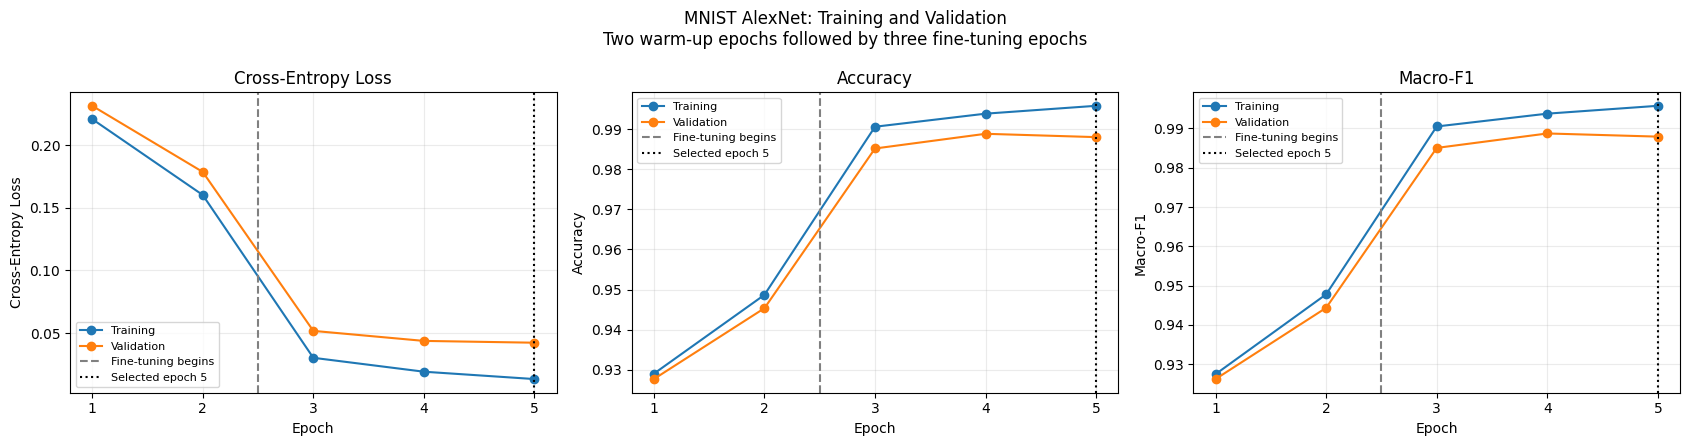

PASS: AlexNet learning curves saved.
Test set remains unevaluated.


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "macro_f1"],
    ["Cross-Entropy Loss", "Accuracy", "Macro-F1"],
):
    ax.plot(
        alex_history_df["epoch"],
        alex_history_df[f"train_{metric}"],
        marker="o",
        label="Training",
    )
    ax.plot(
        alex_history_df["epoch"],
        alex_history_df[f"validation_{metric}"],
        marker="o",
        label="Validation",
    )
    ax.axvline(
        alex_run_config["warmup_epochs"] + 0.5,
        color="gray",
        linestyle="--",
        label="Fine-tuning begins",
    )
    ax.axvline(
        alex_selected_epoch,
        color="black",
        linestyle=":",
        label=f"Selected epoch {alex_selected_epoch}",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_xticks(alex_history_df["epoch"])
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "MNIST AlexNet: Training and Validation\n"
    "Two warm-up epochs followed by three fine-tuning epochs"
)
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "alexnet_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: AlexNet learning curves saved.")
print("Test set remains unevaluated.")

,precision,recall,f1-score,support
digit_or_summary,,,,
0,0.9915,0.9899,0.9907,592.000
1,0.9970,0.9926,0.9948,674.000
2,0.9817,0.9899,0.9858,596.000
3,0.9935,0.9918,0.9927,613.000
4,0.9914,0.9829,0.9871,584.000
5,0.9890,0.9926,0.9908,542.000
6,0.9768,0.9949,0.9858,592.000
7,0.9904,0.9825,0.9864,627.000
8,0.9948,0.9744,0.9845,585.000


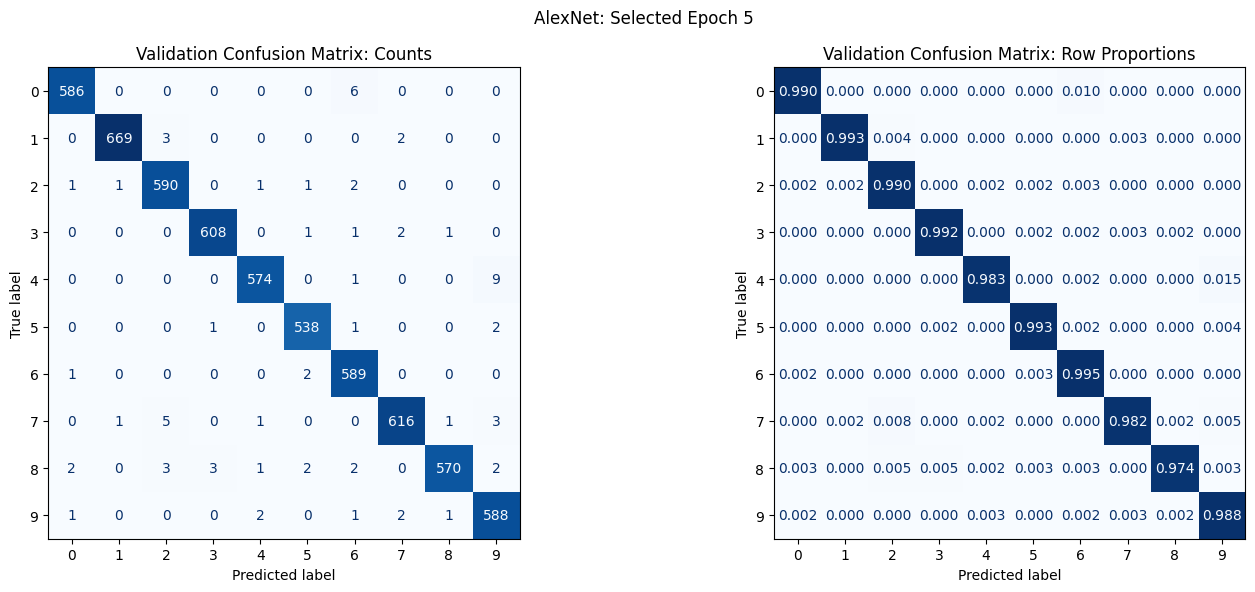

Validation errors: 72
PASS: classification report matches the verified validation metrics.
Test set remains unevaluated.


In [20]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

alex_report = classification_report(
    alex_true_labels,
    alex_predictions,
    labels=np.arange(10),
    target_names=[str(digit) for digit in range(10)],
    output_dict=True,
    zero_division=0,
)
alex_report_df = pd.DataFrame(alex_report).T
alex_report_df.index.name = "digit_or_summary"

assert np.isclose(
    alex_report["accuracy"],
    alex_validation_metrics["accuracy"],
    atol=1e-12,
    rtol=0,
)
assert np.isclose(
    alex_report["macro avg"]["f1-score"],
    alex_validation_metrics["macro_f1"],
    atol=1e-12,
    rtol=0,
)

alex_report_df.to_csv(
    RESULTS_DIR / "alexnet_validation_classification_report.csv"
)
display(alex_report_df.round(4))

alex_counts = confusion_matrix(
    alex_true_labels,
    alex_predictions,
    labels=np.arange(10),
)
alex_proportions = alex_counts / alex_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, matrix, title, value_format in [
    (axes[0], alex_counts, "Validation Confusion Matrix: Counts", "d"),
    (
        axes[1],
        alex_proportions,
        "Validation Confusion Matrix: Row Proportions",
        ".3f",
    ),
]:
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=np.arange(10),
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format=value_format,
        colorbar=False,
    )
    ax.set_title(title)

fig.suptitle(f"AlexNet: Selected Epoch {alex_selected_epoch}")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "alexnet_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Validation errors:", int((alex_true_labels != alex_predictions).sum()))
print("PASS: classification report matches the verified validation metrics.")
print("Test set remains unevaluated.")

In [21]:
comparison_files = [
    "cnn_config.json",
    "cnn_validation_predictions.csv",
    "faster_rcnn_run_config.json",
    "faster_rcnn_metrics.csv",
    "faster_rcnn_validation_predictions.csv",
    "vgg16_run_config.json",
    "vgg16_validation_predictions.csv",
]

comparison_paths = {}
for filename in comparison_files:
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one copy of {filename}; found {len(matches)}."
        )
    comparison_paths[filename] = matches[0]

def load_comparison_config(filename):
    return json.loads(
        comparison_paths[filename].read_text(encoding="utf-8")
    )

cnn_saved_config = load_comparison_config("cnn_config.json")
rcnn_saved_config = load_comparison_config("faster_rcnn_run_config.json")
vgg_saved_config = load_comparison_config("vgg16_run_config.json")

rcnn_saved_metrics = pd.read_csv(
    comparison_paths["faster_rcnn_metrics.csv"]
)
rcnn_validation_rows = rcnn_saved_metrics.loc[
    rcnn_saved_metrics["split"] == "validation"
]
assert len(rcnn_validation_rows) == 1
rcnn_validation_metrics = rcnn_validation_rows.iloc[0]

model_configs = {
    "CNN": cnn_saved_config,
    "Faster R-CNN": rcnn_saved_config,
    "VGG16": vgg_saved_config,
    "AlexNet": alex_run_config,
}
model_predictions = {
    "CNN": pd.read_csv(comparison_paths["cnn_validation_predictions.csv"]),
    "Faster R-CNN": pd.read_csv(
        comparison_paths["faster_rcnn_validation_predictions.csv"]
    ),
    "VGG16": pd.read_csv(
        comparison_paths["vgg16_validation_predictions.csv"]
    ),
    "AlexNet": alex_validation_predictions_df.copy(),
}
expected_metrics = {
    "CNN": cnn_saved_config["validation_metrics"],
    "Faster R-CNN": rcnn_validation_metrics,
    "VGG16": vgg_saved_config["selected_metrics"]["validation"],
    "AlexNet": alex_run_config["selected_metrics"]["validation"],
}

reference = None
comparison_rows = []

for model_name, predictions in model_predictions.items():
    config = model_configs[model_name]
    assert config["split_sha256"] == split_hash
    assert config["test_evaluated"] is False

    columns = ["source_index", "true_digit", "predicted_digit"]
    assert predictions[columns].notna().all().all()
    assert len(predictions) == 6000
    assert predictions["source_index"].is_unique

    predictions = predictions.sort_values("source_index").reset_index(drop=True)
    assert np.isin(predictions["true_digit"], np.arange(10)).all()

    allowed_predictions = (
        np.arange(-1, 10) if model_name == "Faster R-CNN" else np.arange(10)
    )
    assert np.isin(
        predictions["predicted_digit"], allowed_predictions
    ).all()

    image_labels = predictions[["source_index", "true_digit"]].to_numpy()
    if reference is None:
        reference = image_labels
    else:
        assert np.array_equal(reference, image_labels), (
            f"Validation image IDs or labels differ for {model_name}."
        )

    accuracy = accuracy_score(
        predictions["true_digit"], predictions["predicted_digit"]
    )
    macro_f1 = f1_score(
        predictions["true_digit"],
        predictions["predicted_digit"],
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    )

    for metric, value in [("accuracy", accuracy), ("macro_f1", macro_f1)]:
        assert np.isclose(
            value,
            expected_metrics[model_name][metric],
            atol=1e-12,
            rtol=0,
        ), f"Saved {metric} differs for {model_name}."

    comparison_rows.append({
        "model": model_name,
        "selected_epoch": int(config["selected_epoch"]),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "errors": int(
            (predictions["true_digit"] != predictions["predicted_digit"]).sum()
        ),
        "missing_detections": int(
            (predictions["predicted_digit"] == -1).sum()
        ),
        "validation_loss": float(expected_metrics[model_name]["loss"]),
        "loss_type": (
            "Total detection loss"
            if model_name == "Faster R-CNN"
            else "Cross-entropy"
        ),
        "training_seconds": float(config["training_seconds"]),
        "training_minutes": float(config["training_seconds"]) / 60,
        "gpus_used": int(config["gpus_used"]),
    })

part1_comparison_df = pd.DataFrame(comparison_rows)
part1_comparison_df.to_csv(
    RESULTS_DIR / "part1_validation_comparison.csv",
    index=False,
)

part1_protocol = {
    "split_sha256": split_hash,
    "validation_samples": 6000,
    "matching_image_ids_and_labels": True,
    "checkpoint_selection": {
        name: config["checkpoint_selection"]
        for name, config in model_configs.items()
    },
    "timing_scopes": {
        name: config["timing_scope"]
        for name, config in model_configs.items()
    },
    "limitations": [
        "Recorded times use different GPU counts and evaluation workloads.",
        "Faster R-CNN detection loss differs from classifier cross-entropy.",
        "VGG16 and AlexNet use ImageNet pretraining and larger input images.",
        "Configurations use different training budgets and checkpoint rules.",
        "Results describe one run per model.",
    ],
    "test_evaluated": False,
}
(RESULTS_DIR / "part1_comparison_protocol.json").write_text(
    json.dumps(part1_protocol, indent=2),
    encoding="utf-8",
)

display(part1_comparison_df.round(6))

print("PASS: identical validation image IDs and labels across all four models.")
print("PASS: recomputed metrics match the saved experiments.")
print("Part 1 comparison and protocol saved.")
print("Detection loss is interpreted separately.")
print("Recorded run times are not a controlled speed benchmark.")
print("No training or test evaluation performed.")

,model,selected_epoch,accuracy,macro_f1,errors,missing_detections,validation_loss,loss_type,training_seconds,training_minutes,gpus_used
0,CNN,10,0.991500,0.991446,51,0,0.035260,Cross-entropy,32.100712,0.535012,1
1,Faster R-CNN,9,0.988833,0.988829,67,0,0.034690,Total detection loss,3432.163973,57.202733,2
2,VGG16,4,0.991000,0.991022,54,0,0.043520,Cross-entropy,2342.617489,39.043625,2
3,AlexNet,5,0.988000,0.987928,72,0,0.042269,Cross-entropy,374.701611,6.245027,2


PASS: identical validation image IDs and labels across all four models.
PASS: recomputed metrics match the saved experiments.
Part 1 comparison and protocol saved.
Detection loss is interpreted separately.
Recorded run times are not a controlled speed benchmark.
No training or test evaluation performed.


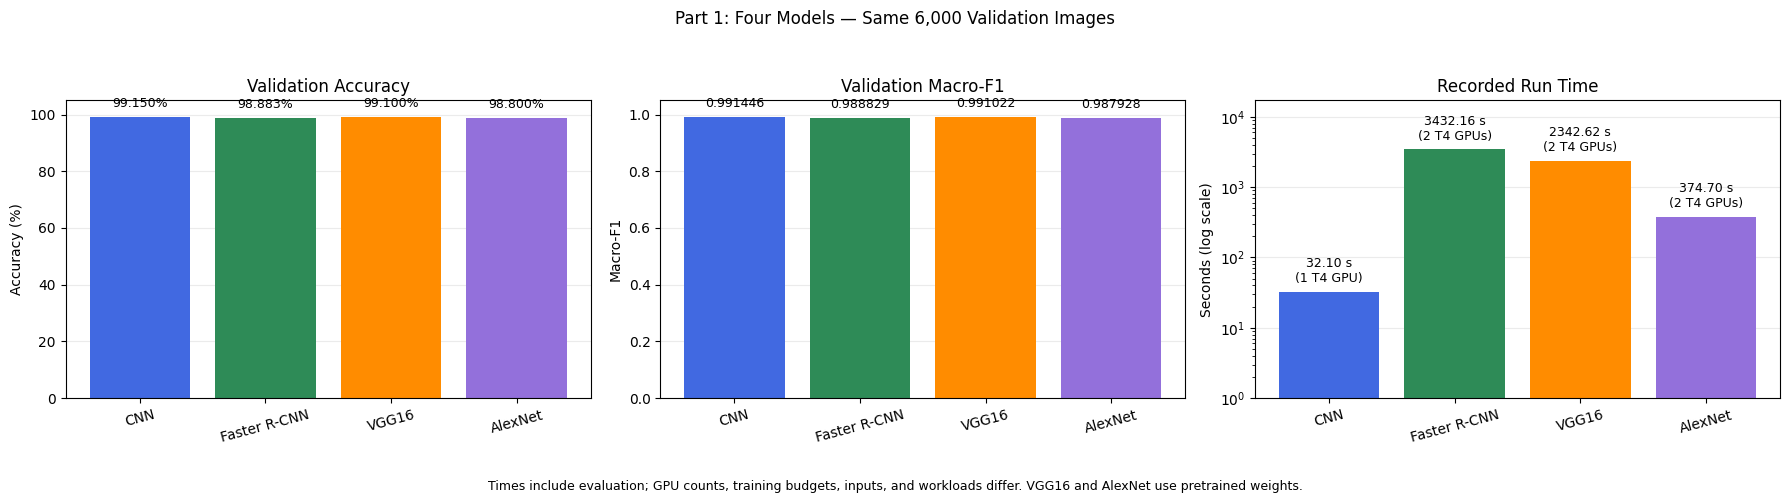

PASS: Part 1 validation comparison chart saved.
Test set remains unevaluated.


In [22]:
plot_data = part1_comparison_df.set_index("model").loc[
    ["CNN", "Faster R-CNN", "VGG16", "AlexNet"]
].reset_index()

colors = ["royalblue", "seagreen", "darkorange", "mediumpurple"]
positions = np.arange(len(plot_data))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    ("accuracy", 100, "Validation Accuracy", "Accuracy (%)"),
    ("macro_f1", 1, "Validation Macro-F1", "Macro-F1"),
    ("training_seconds", 1, "Recorded Run Time", "Seconds (log scale)"),
]

for ax, (column, multiplier, title, ylabel) in zip(axes, panels):
    values = plot_data[column].to_numpy() * multiplier

    ax.bar(positions, values, color=colors)
    ax.set_xticks(positions, plot_data["model"], rotation=15)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    if column == "accuracy":
        ax.set_ylim(0, 105)
    elif column == "macro_f1":
        ax.set_ylim(0, 1.05)
    else:
        ax.set_yscale("log")
        ax.set_ylim(1, values.max() * 5)

    for position, value, gpu_count in zip(
        positions, values, plot_data["gpus_used"]
    ):
        if column == "accuracy":
            label = f"{value:.3f}%"
        elif column == "macro_f1":
            label = f"{value:.6f}"
        else:
            label = (
                f"{value:.2f} s\n"
                f"({gpu_count} T4 GPU{'s' if gpu_count > 1 else ''})"
            )

        ax.annotate(
            label,
            (position, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.suptitle("Part 1: Four Models — Same 6,000 Validation Images")
fig.text(
    0.5,
    0.02,
    "Times include evaluation; GPU counts, training budgets, inputs, and "
    "workloads differ. VGG16 and AlexNet use pretrained weights.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.08, 1, 0.94])
fig.savefig(
    PLOTS_DIR / "part1_validation_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: Part 1 validation comparison chart saved.")
print("Test set remains unevaluated.")

### AlexNet findings and Part 1 conclusion
